# TNG300：潜在銀河量から最終ホスト質量の事後分布へ

**実行環境：公式TNG JupyterLab。元ノートブックは読み書きしません。実データ未実行の実装です。**

入力は赤方偏移 $z$ と真の恒星質量 $\log_{10}(M_\star/M_\odot)$、任意で真のSFR [$M_\odot/\mathrm{yr}$]。
出力は $m_0=\log_{10}(M_{200c,\mathrm{host}}(z=0)/M_\odot)$ のPDF・CDF・中央値・68/95%区間・閾値超過確率。
銀河ごとの等重みで、同一最終ホストへの複数の前駆銀河は残します。

今回の段階は **TNG300-1を母集団モデルとする経験ベイズ／条件付き密度推定** です。
観測誤差、SED推定事前分布、観測selection、宇宙分散、銀河形成モデル誤差、密度推定器のパラメータ不確実性はまだ含みません。
保存銀河標本を、入力条件ごとに再作成する必要はありません。

## 操作
1. このipynbをLabの作業フォルダにアップロード（単独で実行可能）。
2. 設定を確認して上から実行。初回の標本構築には多数のSubLinkアクセスが必要です。
3. 中断後も同じ設定で再開可能。100銀河ごとの追跡チェックポイントとスナップショット別CSVを再利用します。
4. 最後の `model.posterior(z=..., logMstar=..., sfr=...)` で条件を指定。

**最初の読み込みで実データのパス・フィールド・追跡照合が失敗したら、そのエラーを解消してから続行してください。**
コードは入出力障害を「追跡不能」として飲み込みません。

## モデルの定義
各スナップショットで、保存した $N$ 銀河を用いて
$$\hat p(m_0,x\mid z_s)=N^{-1}\sum_i\mathcal N(m_0;m_{0,i},h_0^2)\prod_j\mathcal N(x_j;x_{ij},h_j^2)$$
を構築します。$x=(\log M_\star,\operatorname{asinh}(\mathrm{SFR}/[1M_\odot/yr]))$。
SFRを指定しないときはその次元を周辺化します。
$$\hat p(m_0\mid x,z_s)=\sum_i w_i(x)\mathcal N(m_0;m_{0,i},h_0^2),\quad w_i\propto\prod_{j\in\mathrm{given}}\mathcal N(x_j;x_{ij},h_j^2).$$
単一ガウスを仮定せず、多峰性や裾を表現できます。ただし有限標本と平滑化に依存します。
帯域幅は**観測誤差ではなく密度推定の平滑化幅**です。2つの入力構成は同じ標本を使い、帯域幅をそれぞれ選択します。

帯域幅はtraining内の最終ホスト単位3分割CVで、条件付き対数密度を最大化します。testは選択後に一度評価します。
全スナップショットを通して同じ最終ホストを同じ側へ分割します。異なるホスト間の空間相関は残ります。

スナップショット間の赤方偏移では、隣接する**正規化済み条件付きPDF**をスケール因子で線形混合します。
これは補間の仮定であり、photo-zの誤差積分ではありません。testはスナップショット時刻のみを検証します。
線形質量のPDFが必要なら $p(M_0)=p(m_0)/(M_0\ln 10)$ に変換します。

## 実装：共通関数・データパス

In [1]:
"""TNG300 galaxy-weighted empirical Bayes, latent properties, version 1.
No TNG data are read at import. All output writes require explicit function calls.
"""
from pathlib import Path
from collections import OrderedDict
import hashlib
import json
import sqlite3
import warnings
import numpy as np
import pandas as pd
from scipy.special import logsumexp, ndtr
from scipy.optimize import brentq
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

VERSION = 'latent-host-v1'
LOG2PI = np.log(2 * np.pi)


def digest_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()


def atomic_csv(frame, path):
    """Publish a complete CSV using a unique temporary file in the same directory.

    Concurrent notebooks must never share a fixed <name>.tmp staging path.
    """
    import os
    import tempfile
    path = Path(path)
    fd, tmp_name = tempfile.mkstemp(prefix=path.name+'.', suffix='.tmp', dir=path.parent)
    tmp = Path(tmp_name)
    try:
        with os.fdopen(fd, 'w', encoding='utf-8', newline='') as stream:
            frame.to_csv(stream, index=False)
        tmp.replace(path)
    finally:
        tmp.unlink(missing_ok=True)


def discover_base():
    import os
    if os.environ.get('TNG_OUTPUT_DIR'):
        p = Path(os.environ['TNG_OUTPUT_DIR']).expanduser()
        if not p.is_dir():
            raise FileNotFoundError(p)
        return p.resolve()
    roots = [Path.cwd(), *Path.cwd().parents, Path('/home/tnguser')]
    for root in roots:
        for name in ['TNG300-1', 'L205n2500TNG']:
            p = root / 'sims.TNG' / name / 'output'
            if p.is_dir():
                return p.resolve()
    raise FileNotFoundError('Set TNG_OUTPUT_DIR to the TNG300-1 output directory.')


def discover_epochs(base):
    """All snapshots within 5<=z<=9 plus one bracketing snapshot on each side."""
    import illustris_python as il
    rows = []
    for snap in range(100):
        h = il.groupcat.loadHeader(str(base), snap)
        rows.append((snap, float(h['Redshift'])))
        if rows[-1][1] < 5:
            break
    tab = pd.DataFrame(rows, columns=['snapshot', 'redshift'])
    inside = tab.redshift.between(5, 9)
    selected = set(tab.loc[inside, 'snapshot'].astype(int))
    selected.add(int(tab.loc[tab.redshift.gt(9)].iloc[-1].snapshot))
    selected.add(int(tab.loc[tab.redshift.lt(5)].iloc[0].snapshot))
    return tab[tab.snapshot.isin(selected)].sort_values('snapshot').reset_index(drop=True)




## 実装：銀河標本の構築と子孫追跡

In [2]:
class RootTracker:
    """Read the endpoint directly; RootDescendantID follows the descendant chain.

    SubLink tree IDs are contiguous within a tree/file. Verify both seed and root.
    Unlike onlyMDB, this avoids reading a large intervening off-main-branch subtree.
    I/O/structure errors deliberately propagate; they are not called missing descendants.
    """
    def __init__(self, base):
        import illustris_python as il
        self.il, self.base = il, str(base)
        self.offsets = np.asarray(il.sublink.subLinkOffsets(self.base, 'SubLink'), dtype=np.int64)
        self.handles = OrderedDict()

    def handle(self, chunk):
        import h5py
        if chunk not in self.handles:
            self.handles[chunk] = h5py.File(self.il.sublink.treePath(self.base, 'SubLink', chunk), 'r')
            if len(self.handles) > 8:
                self.handles.popitem(last=False)[1].close()
        self.handles.move_to_end(chunk)
        return self.handles[chunk]

    def trace(self, snap, sid):
        row, _, tree_id = map(int, self.il.sublink.treeOffsets(self.base, int(snap), int(sid), 'SubLink'))
        if row < 0:
            return {'TrackingStatus': 'not_in_tree', 'SubhaloID_z0': -1, 'TerminalSnap': -1}
        chunk = int(np.searchsorted(self.offsets, row, side='right') - 1)
        if chunk < 0:
            raise ValueError('Invalid tree offset')
        f = self.handle(chunk)
        local = row - int(self.offsets[chunk])
        if not 0 <= local < len(f['SubhaloID']):
            raise ValueError('Seed outside file')
        if (int(f['SubhaloID'][local]) != tree_id or int(f['SnapNum'][local]) != snap
                or int(f['SubfindID'][local]) != sid):
            raise ValueError('SubLink seed mismatch')
        root_id = int(f['RootDescendantID'][local])
        root_row = local + root_id - tree_id
        if not 0 <= root_row < len(f['SubhaloID']) or int(f['SubhaloID'][root_row]) != root_id:
            raise ValueError('RootDescendantID/row mismatch')
        end_snap = int(f['SnapNum'][root_row])
        if end_snap < snap or end_snap > 99:
            raise ValueError('Invalid terminal snapshot')
        return {'TrackingStatus': 'success' if end_snap == 99 else 'terminated_before_z0',
                'SubhaloID_z0': int(f['SubfindID'][root_row]) if end_snap == 99 else -1,
                'TerminalSnap': end_snap}

    def close(self):
        for f in self.handles.values():
            f.close()
        self.handles.clear()


def build_catalog(base, out, archive_logmstar_min=8.0, crosscheck_n=5):
    """All physical galaxies (centrals AND satellites), no initial halo-mass cut.

    SubhaloMassType[:,4] = total bound stellar mass; SubhaloSFR = total bound SFR.
    Archive >=1e8 Msun, inference defaults to >=1e9. Neither is a completeness claim.
    Immutable, fingerprinted per-snapshot CSVs; resumable per-seed SQLite checkpoint.
    """
    import glob
    import illustris_python as il
    from tqdm.auto import tqdm
    base, out = Path(base).resolve(), Path(out)
    out.mkdir(parents=True, exist_ok=True)
    epochs = discover_epochs(base)
    head = il.groupcat.loadHeader(str(base), 99)
    h = float(head['HubbleParam'])
    if not (np.isclose(h, .6774, atol=1e-4) and np.isclose(float(head['BoxSize']), 205000)):
        raise ValueError('Expected TNG300 geometry/cosmology')
    # Header particle count distinguishes TNG300-1 from the lower resolutions.
    import h5py
    from illustris_python.snapshot import snapPath
    with h5py.File(snapPath(str(base), int(epochs.iloc[0].snapshot)), 'r') as f:
        n_dm = int(f['Header'].attrs['NumPart_Total'][1])
        high = f['Header'].attrs.get('NumPart_Total_HighWord', np.zeros(6, dtype=np.uint32))
        n_dm += int(high[1]) << 32
    if n_dm != 2500**3:
        raise ValueError(f'Expected TNG300-1 DM count; found {n_dm}')
    paths = glob.glob(il.sublink.treePath(str(base), 'SubLink', '*'))
    for sn in [*epochs.snapshot.astype(int), 99]:
        gc = il.groupcat.gcPath(str(base), sn)
        paths.extend(glob.glob(str(Path(gc).parent / '*.hdf5')))
        paths.append(il.groupcat.offsetPath(str(base), sn))
    stats = [[str(Path(p).resolve()), Path(p).stat().st_size, Path(p).stat().st_mtime_ns]
             for p in sorted(set(paths))]
    meta = dict(version=VERSION, base=str(base), epochs=epochs.to_dict('records'),
                archive_logmstar_min=float(archive_logmstar_min), h=h,
                selection='SubhaloFlag == 1; total stellar mass >= floor; all centrals and satellites',
                mstar_field='SubhaloMassType[:,4]', sfr_field='SubhaloSFR',
                target='z=0 FoF Group_M_Crit200 of SubLink root descendant', files=stats)
    signature = hashlib.sha256(json.dumps(meta, sort_keys=True).encode()).hexdigest()
    cache_dir = out / ('catalog_' + signature[:16])
    cache_dir.mkdir(exist_ok=True)
    (cache_dir / 'manifest.json').write_text(json.dumps(meta, indent=2))
    # A finished signature-matched catalog is immutable; do not republish it.
    combined_path = cache_dir / 'galaxies_all.csv'
    if combined_path.exists():
        cached = pd.read_csv(combined_path)
        if cached.empty or cached.duplicated(['snapshot', 'SubhaloID']).any():
            raise ValueError(f'Invalid completed catalog: {combined_path}')
        if set(cached.snapshot.unique()) != set(epochs.snapshot):
            raise ValueError(f'Incomplete epochs in completed catalog: {combined_path}')
        return cached, cache_dir
    z0_group = np.asarray(il.groupcat.loadSubhalos(str(base), 99, fields='SubhaloGrNr'), dtype=np.int64)
    z0_mass = np.asarray(il.groupcat.loadHalos(str(base), 99, fields='Group_M_Crit200')) * 1e10 / h
    conn = sqlite3.connect(cache_dir / 'tracking.sqlite')
    conn.execute('CREATE TABLE IF NOT EXISTS traces (snap INTEGER, sid INTEGER, payload TEXT, PRIMARY KEY(snap,sid))')
    tracker = RootTracker(base)
    frames = []
    try:
        for ep in epochs.itertuples(index=False):
            snap, z = int(ep.snapshot), float(ep.redshift)
            path = cache_dir / f'galaxies_{snap:03d}.csv'
            if path.exists():
                frames.append(pd.read_csv(path))
                continue
            fields = ['SubhaloMassType', 'SubhaloSFR', 'SubhaloFlag', 'SubhaloGrNr',
                      'SubhaloLenType', 'SubhaloPos']
            cat = il.groupcat.loadSubhalos(str(base), snap, fields=fields)
            first = np.asarray(il.groupcat.loadHalos(str(base), snap, fields='GroupFirstSub'))
            mass = np.asarray(cat['SubhaloMassType'][:, 4], float) * 1e10 / h
            selected = np.flatnonzero((np.asarray(cat['SubhaloFlag']) == 1) & np.isfinite(mass)
                                      & (mass >= 10**archive_logmstar_min))
            done = {int(s): json.loads(p) for s, p in conn.execute('SELECT sid,payload FROM traces WHERE snap=?', (snap,))}
            rows = []
            # Deterministic random seed checks include non-main progenitors when present.
            check_ids = set(np.random.default_rng(42 + snap).choice(selected, min(crosscheck_n, len(selected)), replace=False))
            for k, sid in enumerate(tqdm(selected, desc=f'snap={snap} z={z:.3f}')):
                sid = int(sid)
                r = done.get(sid)
                if r is None:
                    r = tracker.trace(snap, sid)
                    conn.execute('INSERT OR REPLACE INTO traces VALUES (?,?,?)', (snap, sid, json.dumps(r)))
                    if k % 100 == 0:
                        conn.commit()
                if sid in check_ids:
                    t = il.sublink.loadTree(str(base), snap, sid, fields=['SnapNum', 'SubfindID'], onlyMDB=True)
                    end = np.array([], dtype=int) if t is None else np.flatnonzero(np.asarray(t['SnapNum']) == 99)
                    if r['TrackingStatus'] == 'success':
                        if len(end) != 1 or int(t['SubfindID'][end[0]]) != r['SubhaloID_z0']:
                            raise ValueError('Endpoint crosscheck failed')
                    elif len(end):
                        raise ValueError('Unexpected z0 endpoint in crosscheck')
                gr = int(cat['SubhaloGrNr'][sid])
                if not 0 <= gr < len(first):
                    raise ValueError('Invalid source host ID')
                gr0, m0 = -1, np.nan
                r = dict(r)
                if r['TrackingStatus'] == 'success':
                    s0 = r['SubhaloID_z0']
                    if not 0 <= s0 < len(z0_group):
                        raise ValueError('Invalid descendant subhalo')
                    gr0 = int(z0_group[s0])
                    if not 0 <= gr0 < len(z0_mass):
                        raise ValueError('Invalid descendant host')
                    m0 = float(z0_mass[gr0])
                    if not np.isfinite(m0) or m0 <= 0:
                        r['TrackingStatus'] = 'invalid_host_mass'
                        m0 = np.nan
                sfr = float(cat['SubhaloSFR'][sid])
                pos = np.asarray(cat['SubhaloPos'][sid]) / (1000 * h)
                rows.append(dict(snapshot=snap, redshift=z, SubhaloID=sid, GroupID=gr,
                                 is_central=bool(first[gr] == sid), logMstar=float(np.log10(mass[sid])),
                                 SFR=sfr if np.isfinite(sfr) and sfr >= 0 else np.nan,
                                 Nstar=int(cat['SubhaloLenType'][sid, 4]),
                                 x_cMpc=pos[0], y_cMpc=pos[1], z_cMpc=pos[2],
                                 GroupID_z0=gr0, logM0=np.log10(m0) if m0 > 0 else np.nan, **r))
            frame = pd.DataFrame(rows)
            if frame.empty:
                raise RuntimeError(f'No selected galaxies at snapshot {snap}')
            atomic_csv(frame, path)
            frames.append(frame)
            conn.commit()
        combined = pd.concat(frames, ignore_index=True)
        if combined.duplicated(['snapshot', 'SubhaloID']).any():
            raise ValueError('Duplicate source galaxies')
        atomic_csv(combined, cache_dir / 'galaxies_all.csv')
        return combined, cache_dir
    finally:
        conn.commit()
        conn.close()
        tracker.close()




## 実装：標本監査とホスト分割

In [3]:
def prepare_sample(catalog, logmstar_min=9.0):
    """Track missing descendants explicitly; inference is conditional on successful tracking."""
    d = catalog.loc[catalog.logMstar.ge(logmstar_min)].copy()
    if d.empty:
        raise ValueError('Empty stellar-mass selection')
    d['mass_bin'] = np.floor(d.logMstar * 2) / 2
    d['tracked'] = d.TrackingStatus.eq('success') & np.isfinite(d.logM0) & d.GroupID_z0.ge(0)
    report = d.groupby(['snapshot', 'redshift', 'mass_bin'], observed=True).agg(
        N=('tracked', 'size'), N_tracked=('tracked', 'sum'), tracking_fraction=('tracked', 'mean'),
        median_Nstar=('Nstar', 'median')).reset_index()
    if (report.tracking_fraction < .95).any():
        warnings.warn('Some mass/redshift bins have <95% tracking success. Inspect completeness.csv; '
                      'posterior is conditional on successful tracking and is not corrected for missing descendants.')
    valid = d.loc[d.tracked].copy()
    if valid.empty:
        raise ValueError('No valid descendants')
    if not np.isfinite(valid.SFR).all() or (valid.SFR < 0).any():
        raise ValueError('Missing/negative SFR: inspect catalog; do not silently change the common sample')
    valid['asinhSFR'] = np.arcsinh(valid.SFR)  # SFR / (1 Msun/yr), including exact zero
    valid['GroupID_z0'] = valid.GroupID_z0.astype(np.int64)
    return valid.reset_index(drop=True), report


def host_split(frame, test_fraction=.2, seed=42):
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_fraction, random_state=seed)
    i, j = next(splitter.split(frame, groups=frame.GroupID_z0))
    train, test = frame.iloc[i].copy(), frame.iloc[j].copy()
    assert set(train.GroupID_z0).isdisjoint(test.GroupID_z0)
    # One global split across ALL epochs, so progenitors at different z cannot leak.
    for sn in frame.snapshot.unique():
        if train[train.snapshot.eq(sn)].GroupID_z0.nunique() < 6 or test[test.snapshot.eq(sn)].empty:
            raise ValueError(f'Insufficient host support at snapshot {sn}')
    return train, test




## 実装：条件付き確率密度

In [4]:
class Posterior:
    """Gaussian mixture density in m=log10(M0/Msun), NOT density per linear mass."""
    def __init__(self, means, weights, width, hosts, metadata=None):
        self.means, self.weights = np.asarray(means, float), np.asarray(weights, float)
        self.width = float(width)
        self.hosts = np.asarray(hosts)
        if (len(self.means) == 0 or self.means.shape != self.weights.shape or len(self.hosts) != len(self.means)
                or not np.isfinite(self.means).all() or not np.isfinite(self.weights).all()
                or (self.weights < 0).any() or self.weights.sum() <= 0
                or not np.isfinite(width) or width <= 0):
            raise ValueError('Invalid mixture')
        self.weights = self.weights / self.weights.sum()
        self.metadata = metadata or {}

    def cdf(self, m):
        return float(np.dot(self.weights, ndtr((float(m) - self.means) / self.width)))

    def logpdf(self, m):
        with np.errstate(divide='ignore'):
            lw = np.log(self.weights)
        return float(logsumexp(lw - .5 * ((float(m) - self.means) / self.width)**2)
                     - np.log(self.width) - .5 * LOG2PI)

    def quantile(self, q):
        if not 0 < q < 1:
            raise ValueError('Quantile must lie strictly between 0 and 1')
        return brentq(lambda m: self.cdf(m) - q, self.means.min() - 12*self.width,
                      self.means.max() + 12*self.width)

    def summary(self):
        wh = pd.Series(self.weights).groupby(self.hosts).sum().to_numpy()
        return dict(q025=self.quantile(.025), q16=self.quantile(.16), median=self.quantile(.5),
                    q84=self.quantile(.84), q975=self.quantile(.975),
                    p_ge_1e13=1-self.cdf(13), p_ge_1e14=1-self.cdf(14), p_ge_1e15=1-self.cdf(15),
                    ESS_galaxy=1/np.sum(self.weights**2), ESS_host=1/np.sum(wh**2), **self.metadata)

    def table(self, n=600):
        grid = np.linspace(self.means.min()-8*self.width, self.means.max()+8*self.width, n)
        return pd.DataFrame({'logM0': grid, 'pdf_per_dex': [np.exp(self.logpdf(x)) for x in grid],
                             'cdf': [self.cdf(x) for x in grid]})


def conditional(frame, query, bandwidths, ywidth, check_support=True):
    """Condition a product-Gaussian joint KDE on exact latent values.

    Equal weights on source GALAXIES are the prior. Kernel bandwidth is statistical
    smoothing, not a measurement error. Omitted SFR is analytically marginalized.
    """
    cols = list(query)
    if not cols or set(cols) - {'logMstar', 'asinhSFR'}:
        raise ValueError('Unsupported or empty latent query')
    x, q = frame[cols].to_numpy(float), np.array([query[k] for k in cols], float)
    bw = np.array([bandwidths[k] for k in cols], float)
    if len(x) == 0 or not np.isfinite(x).all() or not np.isfinite(q).all() or (bw <= 0).any():
        raise ValueError('Invalid query, bandwidth or empty sample')
    distance2 = np.sum(((x-q)/bw)**2, axis=1)
    logw = -.5 * distance2
    w = np.exp(logw-logsumexp(logw))
    host_w = pd.Series(w).groupby(frame.GroupID_z0.to_numpy()).sum().to_numpy()
    diagnostics = dict(nearest_kernel_distance=float(np.sqrt(distance2.min())),
                       ESS_galaxy=1/np.sum(w*w), ESS_host=1/np.sum(host_w*host_w))
    outside = np.any(q < x.min(axis=0)) or np.any(q > x.max(axis=0))
    poor = outside or diagnostics['nearest_kernel_distance'] > 3 or diagnostics['ESS_host'] < 10 or diagnostics['ESS_galaxy'] < 20
    if check_support and poor:
        raise ValueError(f'Insufficient support / extrapolation: {diagnostics}; query outside range={outside}. '
                         'Use a broader catalog or inspect explicitly; do not report this as a reliable posterior.')
    return Posterior(frame.logM0.to_numpy(), w, ywidth, frame.GroupID_z0.to_numpy(),
                     {'support_ok': not poor, 'nearest_kernel_distance': diagnostics['nearest_kernel_distance']})




## 実装：帯域幅選択と未使用test評価

In [5]:
FEATURE_SETS = {'mstar': ['logMstar'], 'mstar_sfr': ['logMstar', 'asinhSFR']}
BASE_BW = {'logMstar': .2, 'asinhSFR': .5}


def select_bandwidths(train, validation_cap_per_snap=100, seed=42, diagnostics_path=None):
    """3 host folds; minimize conditional negative log density of logM0.

    Validation cap is a deterministic random subset, shared by all candidates.
    Equal mean weight per epoch prevents snapshot abundance from choosing the model.
    No test galaxies are used. Separate tuning for the two feature sets.
    Only epochs supported in ALL folds enter CV; omitted epochs remain in the model.
    Bandwidths at omitted epochs are transferred, not validated by this CV.
    """
    splits = list(GroupKFold(3).split(train, groups=train.GroupID_z0))
    diagnostics = []
    for fold, (it, iv) in enumerate(splits):
        tr, va = train.iloc[it], train.iloc[iv]
        for snap in sorted(train.snapshot.unique()):
            a = tr.loc[tr.snapshot.eq(snap)]
            b = va.loc[va.snapshot.eq(snap)]
            diagnostics.append(dict(
                fold=fold, snapshot=int(snap),
                redshift=float(train.loc[train.snapshot.eq(snap), 'redshift'].iloc[0]),
                N_train=len(a), N_validation=len(b),
                N_hosts_train=a.GroupID_z0.nunique(), N_hosts_validation=b.GroupID_z0.nunique(),
                fold_ok=len(a) >= 20 and not b.empty))
    diagnostics = pd.DataFrame(diagnostics)
    eligible = diagnostics.groupby('snapshot').fold_ok.all()
    cv_epochs = eligible.index[eligible].tolist()
    diagnostics['used_for_cv'] = diagnostics.snapshot.isin(cv_epochs)
    diagnostics['reason'] = np.where(
        diagnostics.used_for_cv, 'included',
        'excluded from all folds: at least one fold has N_train < 20 or N_validation == 0')
    if diagnostics_path is not None:
        diagnostics.to_csv(diagnostics_path, index=False)
    excluded = eligible.index[~eligible].tolist()
    if excluded:
        warnings.warn(f'CV excludes snapshots {excluded} from ALL candidates/folds. '
                      'Their model bandwidths are transferred from supported epochs; '
                      'inspect cv_fold_diagnostics.csv and per-snapshot test support.')
    if not cv_epochs:
        raise ValueError('No snapshot supports 3-fold host CV. Inspect fold diagnostics; '
                         'revise the population selection or CV design.')
    records = []
    for name, cols in FEATURE_SETS.items():
        for scale in [.5, 1., 2.]:
            bw = {k: v*scale for k, v in BASE_BW.items()}
            for yw in [.10, .20, .35]:
                for fold, (it, iv) in enumerate(splits):
                    tr, va = train.iloc[it], train.iloc[iv]
                    assert set(tr.GroupID_z0).isdisjoint(va.GroupID_z0)
                    for snap in cv_epochs:
                        a = tr.loc[tr.snapshot.eq(snap)]
                        b = va.loc[va.snapshot.eq(snap)]
                        if len(a) < 20 or b.empty:
                            raise ValueError(f'Too few training/validation galaxies at {snap}')
                        b = b.sample(min(validation_cap_per_snap, len(b)), random_state=seed+fold+int(snap))
                        loss = []
                        for _, row in b.iterrows():
                            p = conditional(a, row[cols].to_dict(), bw, yw, check_support=False)
                            loss.append(-p.logpdf(row.logM0))
                        records.append(dict(feature_set=name, scale=scale, ywidth=yw, fold=fold,
                                            snapshot=int(snap), n=len(loss), nll=float(np.mean(loss))))
                print(f'CV {name}: scale={scale}, target_width={yw} complete', flush=True)
    cv = pd.DataFrame(records)
    selected = {}
    for name in FEATURE_SETS:
        scores = cv[cv.feature_set.eq(name)].groupby(['scale', 'ywidth']).nll.mean()
        scale, yw = scores.idxmin()
        selected[name] = {'bandwidths': {k: v*float(scale) for k,v in BASE_BW.items()},
                          'ywidth': float(yw), 'cv_nll': float(scores.min())}
    return selected, cv, diagnostics


def evaluate(train, test, selected, test_cap_per_snap=300, seed=777):
    """Frozen test diagnostics. PIT intervals assess central 68/95% coverage.

    No claim of independent rows across snapshots or shared final hosts.
    Sparse/unsupported test queries remain included and are visibly flagged.
    """
    rows = []
    for snap in sorted(test.snapshot.unique()):
        a = train[train.snapshot.eq(snap)]
        b = test[test.snapshot.eq(snap)]
        b = b.sample(min(test_cap_per_snap, len(b)), random_state=seed+int(snap))
        for name, cols in FEATURE_SETS.items():
            cfg = selected[name]
            for _, row in b.iterrows():
                p = conditional(a, row[cols].to_dict(), cfg['bandwidths'], cfg['ywidth'], check_support=False)
                pit = p.cdf(row.logM0)
                prior = Posterior(a.logM0.to_numpy(), np.ones(len(a)), cfg['ywidth'], a.GroupID_z0.to_numpy())
                prob = 1-p.cdf(14)
                rows.append(dict(feature_set=name, snapshot=int(snap), redshift=row.redshift,
                                 SubhaloID=int(row.SubhaloID), GroupID_z0=int(row.GroupID_z0),
                                 logMstar=row.logMstar, logM0=row.logM0, pit=pit,
                                 nll=-p.logpdf(row.logM0), prior_nll=-prior.logpdf(row.logM0),
                                 coverage68=.16 <= pit <= .84, coverage95=.025 <= pit <= .975,
                                 p_cluster=prob, brier=(prob-float(row.logM0>=14))**2,
                                 support_ok=p.metadata['support_ok']))
    raw = pd.DataFrame(rows)
    summary = raw.groupby(['feature_set', 'snapshot', 'redshift']).agg(
        N=('pit','size'), N_hosts=('GroupID_z0','nunique'), NLL=('nll','mean'),
        prior_NLL=('prior_nll','mean'), coverage68=('coverage68','mean'), coverage95=('coverage95','mean'),
        Brier=('brier','mean'), supported_fraction=('support_ok','mean')).reset_index()
    return raw, summary




## 実装：利用者向け推論API

In [6]:
class LatentHostModel:
    def __init__(self, train, selected, logmstar_min=9.):
        self.train = train.copy()
        self.selected, self.logmstar_min = selected, float(logmstar_min)
        self.epochs = train[['snapshot', 'redshift']].drop_duplicates().sort_values('redshift')
        if self.epochs.snapshot.duplicated().any() or self.epochs.redshift.duplicated().any():
            raise ValueError('Ambiguous snapshot/redshift mapping')

    def posterior(self, z, logMstar, sfr=None):
        """z in [5,9]; exact latent stellar mass in log10 Msun, SFR in Msun/yr.

        At non-snapshot redshifts, linearly mix the TWO normalized conditional
        distributions in scale factor a=1/(1+z). This is an explicit interpolation
        approximation, NOT extra independent data and NOT a redshift likelihood.
        """
        vals = [z, logMstar] if sfr is None else [z, logMstar, sfr]
        if not np.isfinite(vals).all() or not 5 <= z <= 9 or logMstar < self.logmstar_min:
            raise ValueError(f'Use 5<=z<=9, logMstar>={self.logmstar_min}, finite latent values')
        if sfr is not None and sfr < 0:
            raise ValueError('SFR must be nonnegative; zero is valid')
        name = 'mstar' if sfr is None else 'mstar_sfr'
        query = {'logMstar': float(logMstar)}
        if sfr is not None:
            query['asinhSFR'] = float(np.arcsinh(sfr))
        cfg = self.selected[name]
        zs = self.epochs.redshift.to_numpy()
        exact = np.flatnonzero(np.isclose(zs, z, rtol=0, atol=1e-8))
        if len(exact):
            indices, mix = [int(exact[0])], [1.]
        else:
            j = int(np.searchsorted(zs, z))
            if j == 0 or j == len(zs):
                raise ValueError('Catalog does not bracket requested z')
            a0, a1, aq = 1/(1+zs[j-1]), 1/(1+zs[j]), 1/(1+z)
            t = (aq-a0)/(a1-a0)
            indices, mix = [j-1, j], [1-t, t]
        pieces, details = [], []
        for ix, weight in zip(indices, mix):
            ep = self.epochs.iloc[ix]
            part = self.train[self.train.snapshot.eq(ep.snapshot)]
            p = conditional(part, query, cfg['bandwidths'], cfg['ywidth'])
            pieces.append((p, weight))
            details.append(dict(snapshot=int(ep.snapshot), z=float(ep.redshift), weight=float(weight)))
        if logMstar-self.logmstar_min < 3*cfg['bandwidths']['logMstar']:
            warnings.warn('Query is close to the model stellar-mass floor. Check sensitivity to a lower floor; '
                          'the result is conditional on the selected population.')
        if len(indices)>1:
            warnings.warn('Interpolating conditional PDFs between snapshots; interpolation has not been '
                          'validated by the per-snapshot test. Epoch details are returned.')
        return Posterior(np.concatenate([p.means for p,w in pieces]),
                         np.concatenate([p.weights*w for p,w in pieces]), cfg['ywidth'],
                         np.concatenate([p.hosts for p,w in pieces]),
                         dict(z=float(z), logMstar=float(logMstar), sfr=sfr, feature_set=name,
                              epochs=details, support_ok=True,
                              population='physical galaxies above model mass floor; successfully tracked to z0',
                              model='empirical joint KDE; simulation conditional; exact latent inputs'))


## 実行設定
恒星質量は `SubhaloMassType[:,4]`（全束縛恒星質量）、SFRは `SubhaloSFR`（全束縛ガスのSFR）。
観測での開口内質量と同一ではありません。`SubhaloFlag == 1`、中心・衛星を共に含み、初期ハロー質量で切りません。

保存下限は $10^8M_\odot$、推論の暫定下限は $10^9M_\odot$。これは完全性・収束を保証する閾値ではありません。
`Nstar`と下限への感度を確認してください。保存下限を変えると新しい標本を作りますが、推論下限だけの変更は保存標本を再利用します。
CV/testの上限は評価点数のみを制限し、training標本を間引きません。赤方偏移ごとに評価し、異なる時刻の行を独立観測として扱いません。

In [7]:
import os, platform, sys
from IPython.display import display
import matplotlib.pyplot as plt
# 必要な場合のみ明示指定：
# os.environ['TNG_OUTPUT_DIR'] = '/home/tnguser/sims.TNG/TNG300-1/output'
BASE = discover_base()
# リポジトリ直下・protohalo・notebooks のいずれから実行しても同じcacheへ保存。
PROTOHALO_DIR = next(
    (candidate for root in (Path.cwd(), *Path.cwd().parents)
     for candidate in (root / 'protohalo', root)
     if candidate.name == 'protohalo' and (candidate / 'notebooks').is_dir()),
    None,
)
if PROTOHALO_DIR is None:
    raise FileNotFoundError('protohalo が見つかりません。tng-work リポジトリ内から実行してください。')
RUN_ROOT = PROTOHALO_DIR / 'cache' / 'tng300_bayesian_latent_results'
RUN_ROOT.mkdir(parents=True, exist_ok=True)
ARCHIVE_LOGMSTAR_MIN = 8.0
MODEL_LOGMSTAR_MIN = 9.0
CV_CAP_PER_SNAP = 100
TEST_CAP_PER_SNAP = 300
SEED = 42
print('TNG input:', BASE)
print('New outputs:', RUN_ROOT.resolve())


TNG input: /home/tnguser/sims.TNG/L205n2500TNG/output
New outputs: /home/tnguser/tng-work/protohalo/cache/tng300_bayesian_latent_results


## 1. 保存標本を作る（初回のみ重い処理）
全 $5\le z\le9$ スナップショットと両端の補間用隣接スナップショットを読みます。
SubLinkの最終子孫がsnapshot 99に到達したときだけ、そのFoFホストの `Group_M_Crit200` を採用します。
合体後は合体先のホストへ対応付けます。「銀河自身が生き残る確率」を推定するモデルではありません。
追跡未完了の銀河も保存し、後で除外率を確認します。

In [8]:
catalog, CATALOG_DIR = build_catalog(BASE, RUN_ROOT, ARCHIVE_LOGMSTAR_MIN)
print('Catalog:', CATALOG_DIR)
display(catalog.groupby(['snapshot', 'redshift', 'TrackingStatus']).size().rename('N').reset_index())
display(catalog.head())

Catalog: /home/tnguser/tng-work/protohalo/cache/tng300_bayesian_latent_results/catalog_53af35e58a768080


,snapshot,redshift,TrackingStatus,N
0,6,9.002340,success,2412
1,7,8.449476,success,4921
2,8,8.012173,success,8321
3,9,7.595107,success,13508
4,10,7.236276,success,20114
5,10,7.236276,terminated_before_z0,1
6,11,7.005417,not_in_tree,1
7,11,7.005417,success,25810
8,11,7.005417,terminated_before_z0,1
9,12,6.491598,success,43285


,snapshot,redshift,SubhaloID,GroupID,is_central,logMstar,SFR,Nstar,x_cMpc,y_cMpc,z_cMpc,GroupID_z0,logM0,TrackingStatus,SubhaloID_z0,TerminalSnap
0,6,9.00234,0,0,True,9.601715,71.177063,836,78.053670,117.99342,197.53226,5,14.865416,success,33174,99
1,6,9.00234,1,0,False,8.401018,2.462698,42,78.332306,118.02188,197.58913,5,14.865416,success,33174,99
2,6,9.00234,5,1,True,9.333946,39.531788,688,77.482050,117.04402,197.68047,5,14.865416,success,33174,99
3,6,9.00234,6,1,False,8.436382,3.383914,24,77.438900,116.97683,197.70145,5,14.865416,success,33174,99
4,6,9.00234,15,2,True,8.418451,4.592360,92,253.860750,63.89220,246.63123,479,13.872346,success,506164,99


## 2. 標本品質とtraining/test分割
追跡未完了銀河の $M_0$ は不明なので補完しません。得られる分布は追跡成功に条件付けられます。
質量・赤方偏移別に追跡成功率が低い場合、全母集団の結果と解釈しないでください。
元のCSVと推論設定からIDを作り、同じデータ・設定で結果を再現します。

In [9]:
if MODEL_LOGMSTAR_MIN < ARCHIVE_LOGMSTAR_MIN:
    raise ValueError('推論下限は保存下限以上にしてください')
sample, completeness = prepare_sample(catalog, MODEL_LOGMSTAR_MIN)
settings = dict(version=VERSION, cv_policy='all-fold-supported-epochs-v1', catalog_sha256=digest_file(CATALOG_DIR/'galaxies_all.csv'),
                model_logmstar_min=MODEL_LOGMSTAR_MIN, seed=SEED,
                cv_cap=CV_CAP_PER_SNAP, test_cap=TEST_CAP_PER_SNAP)
run_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
RESULTS = RUN_ROOT / ('inference_' + run_id)
RESULTS.mkdir(exist_ok=True)
completeness.to_csv(RESULTS/'completeness.csv', index=False)
display(completeness)
train, test = host_split(sample, seed=SEED)
split_table = pd.concat([train.assign(split='train'), test.assign(split='test')])
split_table[['snapshot','SubhaloID','GroupID_z0','split']].to_csv(RESULTS/'split.csv', index=False)
display(split_table.groupby(['snapshot','split']).agg(N=('SubhaloID','size'), N_hosts=('GroupID_z0','nunique')))
print('Shared final hosts:', len(set(train.GroupID_z0) & set(test.GroupID_z0)))

,snapshot,redshift,mass_bin,N,N_tracked,tracking_fraction,median_Nstar
0,6,9.002340,9.0,26,26,1.000000,423.0
1,6,9.002340,9.5,2,2,1.000000,800.5
2,7,8.449476,9.0,84,84,1.000000,383.0
3,7,8.449476,9.5,15,15,1.000000,755.0
4,8,8.012173,9.0,187,187,1.000000,357.0
5,8,8.012173,9.5,37,37,1.000000,840.0
6,8,8.012173,10.0,4,4,1.000000,1464.0
7,9,7.595107,9.0,362,362,1.000000,343.0
8,9,7.595107,9.5,86,86,1.000000,809.0
9,9,7.595107,10.0,13,13,1.000000,1734.0


N  N_hosts
snapshot split                
6        test       3        3
         train     25       20
7        test      20       16
         train     79       66
8        test      43       34
         train    185      149
9        test      91       66
         train    370      272
10       test     168      112
         train    666      455
11       test     244      150
         train    944      614
12       test     517      265
         train   1965     1114
13       test    1022      466
         train   3884     1906
14       test    1272      551
         train   4805     2279
15       test    1892      752
         train   7068     3054
16       test    2688     1011
         train  10005     4072
17       test    3530     1247
         train  12988     4987

Shared final hosts: 0


## 3. trainingのみで平滑化幅を選択
候補は恒星質量の幅0.1/0.2/0.4 dex、SFR変換量の幅0.25/0.5/1.0（恒星質量幅と連動）、
最終質量の幅0.10/0.20/0.35 dexです。最良値が候補端にある場合は次の研究段階で探索を検討します。
test結果を見て探索を変更した場合、同じtestを未使用テストと呼べなくなります。

各fold・各時刻の学習／検証銀河数と最終ホスト数を `cv_fold_diagnostics.csv` に保存します。
いずれかのfoldで学習銀河数が20未満、または検証銀河数が0の時刻は、全候補・全foldのCVから共通して除外します。
これは標本不足を解消する処置ではなく、十分な標本がある時刻で選んだ帯域幅を疎な時刻にも共用する仮定です。
除外時刻の銀河はtraining/testに残し、testの時刻別評価と推論時のサポート判定も維持します。
特にtestが数銀河しかない時刻では、較正精度を十分に評価できません。
全時刻が除外された場合は診断表を保存して停止します。


In [10]:
selected, cv, cv_diagnostics = select_bandwidths(
    train, CV_CAP_PER_SNAP, SEED, diagnostics_path=RESULTS/'cv_fold_diagnostics.csv')
display(cv_diagnostics)
settings['cv_snapshots_used'] = sorted(cv_diagnostics.loc[cv_diagnostics.used_for_cv, 'snapshot'].unique().tolist())
settings['cv_snapshots_excluded'] = sorted(cv_diagnostics.loc[~cv_diagnostics.used_for_cv, 'snapshot'].unique().tolist())
cv.to_csv(RESULTS/'cv_scores.csv', index=False)
(RESULTS/'selected_bandwidths.json').write_text(json.dumps(selected, indent=2))
display(pd.DataFrame(selected).T)


/tmp/ipykernel_11616/3325689036.py:38: UserWarning: CV excludes snapshots [6] from ALL candidates/folds. Their model bandwidths are transferred from supported epochs; inspect cv_fold_diagnostics.csv and per-snapshot test support.
  warnings.warn(f'CV excludes snapshots {excluded} from ALL candidates/folds. '


CV mstar: scale=0.5, target_width=0.1 complete
CV mstar: scale=0.5, target_width=0.2 complete
CV mstar: scale=0.5, target_width=0.35 complete
CV mstar: scale=1.0, target_width=0.1 complete
CV mstar: scale=1.0, target_width=0.2 complete
CV mstar: scale=1.0, target_width=0.35 complete
CV mstar: scale=2.0, target_width=0.1 complete
CV mstar: scale=2.0, target_width=0.2 complete
CV mstar: scale=2.0, target_width=0.35 complete
CV mstar_sfr: scale=0.5, target_width=0.1 complete
CV mstar_sfr: scale=0.5, target_width=0.2 complete
CV mstar_sfr: scale=0.5, target_width=0.35 complete
CV mstar_sfr: scale=1.0, target_width=0.1 complete
CV mstar_sfr: scale=1.0, target_width=0.2 complete
CV mstar_sfr: scale=1.0, target_width=0.35 complete
CV mstar_sfr: scale=2.0, target_width=0.1 complete
CV mstar_sfr: scale=2.0, target_width=0.2 complete
CV mstar_sfr: scale=2.0, target_width=0.35 complete


,fold,snapshot,redshift,N_train,N_validation,N_hosts_train,N_hosts_validation,fold_ok,used_for_cv,reason
0,0,6,9.002340,16,9,12,8,False,False,excluded from all folds: at least one fold has...
1,0,7,8.449476,49,30,41,25,True,True,included
2,0,8,8.012173,122,63,98,51,True,True,included
3,0,9,7.595107,248,122,183,89,True,True,included
4,0,10,7.236276,426,240,295,160,True,True,included
5,0,11,7.005417,609,335,406,208,True,True,included
6,0,12,6.491598,1307,658,745,369,True,True,included
7,0,13,6.010757,2606,1278,1274,632,True,True,included
8,0,14,5.846614,3201,1604,1521,758,True,True,included
9,0,15,5.529766,4725,2343,2039,1015,True,True,included


,bandwidths,ywidth,cv_nll
mstar,"{'logMstar': 0.4, 'asinhSFR': 1.0}",0.2,1.004655
mstar_sfr,"{'logMstar': 0.4, 'asinhSFR': 1.0}",0.2,1.002739


## 4. testで確率分布を検証
NLLは小さいほど良好。`prior_NLL`は同じ時刻の無条件の最終質量分布との比較です。
68/95%の包含率、PIT、銀河団所属確率のBrierを表示します。
サポート不足のtest点も除外せず、`supported_fraction`として示します。
数値は未実行のため未確定です。良好な較正を保証する自動合格判定は行いません。

,feature_set,snapshot,redshift,N,N_hosts,NLL,prior_NLL,coverage68,coverage95,Brier,supported_fraction
0,mstar,6,9.002340,3,3,1.007773,0.992391,1.000000,1.000000,0.226506,1.000000
1,mstar,7,8.449476,20,16,0.989808,0.988409,0.900000,1.000000,0.244227,0.950000
2,mstar,8,8.012173,43,34,0.877406,0.882689,0.790698,1.000000,0.250237,1.000000
3,mstar,9,7.595107,91,66,0.861992,0.867024,0.802198,0.989011,0.254287,1.000000
4,mstar,10,7.236276,168,112,0.827824,0.832250,0.791667,0.994048,0.252164,0.988095
5,mstar,11,7.005417,244,150,0.846309,0.851311,0.774590,0.991803,0.250695,1.000000
6,mstar,12,6.491598,300,186,0.825227,0.827627,0.800000,0.996667,0.246050,1.000000
7,mstar,13,6.010757,300,200,0.937451,0.946819,0.713333,0.986667,0.242375,1.000000
8,mstar,14,5.846614,300,199,0.885618,0.898761,0.813333,0.993333,0.243540,1.000000
9,mstar,15,5.529766,300,215,0.940735,0.951149,0.776667,0.990000,0.229381,1.000000


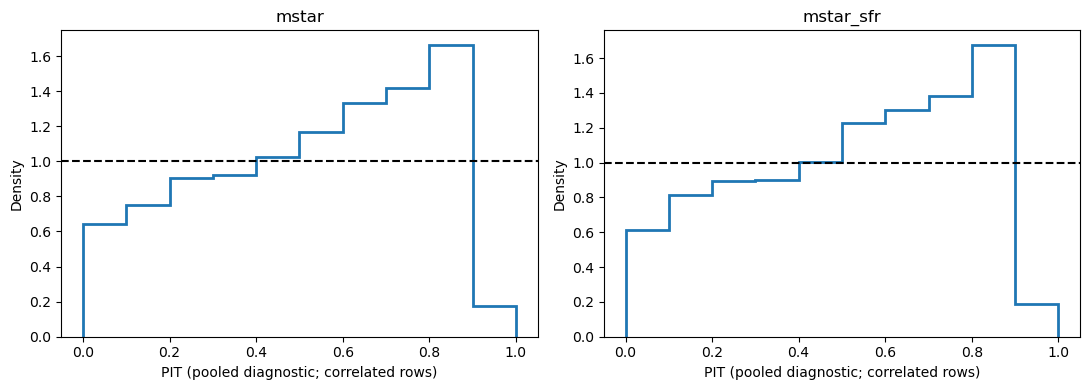

933

In [11]:
test_predictions, validation = evaluate(train, test, selected, TEST_CAP_PER_SNAP)
test_predictions.to_csv(RESULTS/'test_predictions.csv', index=False)
validation.to_csv(RESULTS/'validation.csv', index=False)
display(validation)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, name in zip(axes, FEATURE_SETS):
    pit = test_predictions.loc[test_predictions.feature_set.eq(name), 'pit']
    ax.hist(pit, bins=np.linspace(0,1,11), density=True, histtype='step', linewidth=2)
    ax.axhline(1, color='k', linestyle='--')
    ax.set(xlabel='PIT (pooled diagnostic; correlated rows)', ylabel='Density', title=name)
fig.tight_layout()
fig.savefig(RESULTS/'pit.png', dpi=160)
plt.show()
import scipy, sklearn
settings['versions'] = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                            scipy=scipy.__version__, sklearn=sklearn.__version__)
settings['selected'] = selected
settings['inference_uses'] = 'training only; no refit on test'
(RESULTS/'run_metadata.json').write_text(json.dumps(settings, indent=2))


## 5. 潜在物理量を入力して事後分布を出力
例の数値は利用者が変更する入力例で、特定の観測銀河を表していません。
SFRの単位は $M_\odot/\mathrm{yr}$、0は有効値、`None`なら条件に含めません。
**実測の恒星質量・SFRの点推定値を、誤差なしの真値と同一視して適用しないでください。**

サポート不足（重みの有効銀河数<20、有効ホスト数<10、範囲外など）では推論を停止します。
ESSは支持の集中度の指標で、事後区間の信頼度や独立標本数の保証ではありません。
モデルはtestを含めて再学習せず、検証したtraining標本のまま使います。

## 入力範囲の確認：恒星質量と全ホスト質量のヒストグラム
各時刻の保存銀河（保存下限以上）と、実際に推論に使うtraining銀河を重ねて表示します。
横軸は `logMstar` 入力と同じ対数質量、縦軸はビン内の個数です。破線は推論下限です。
trainingの少ない質量域では、範囲内でも推論時のサポート判定に通らない場合があります。

最後の図はsnapshot 99の全FoFグループから直接読み込んだ、正の有限な `Group_M_Crit200` の分布です。
各ホストを1回だけ数えます。高赤方偏移銀河の子孫だけの分布や、このモデルの銀河重み付き事前分布とは異なります。
質量ゼロ・非有限値は除外数を表示します。図とビンごとの個数を `RESULTS` に保存します。


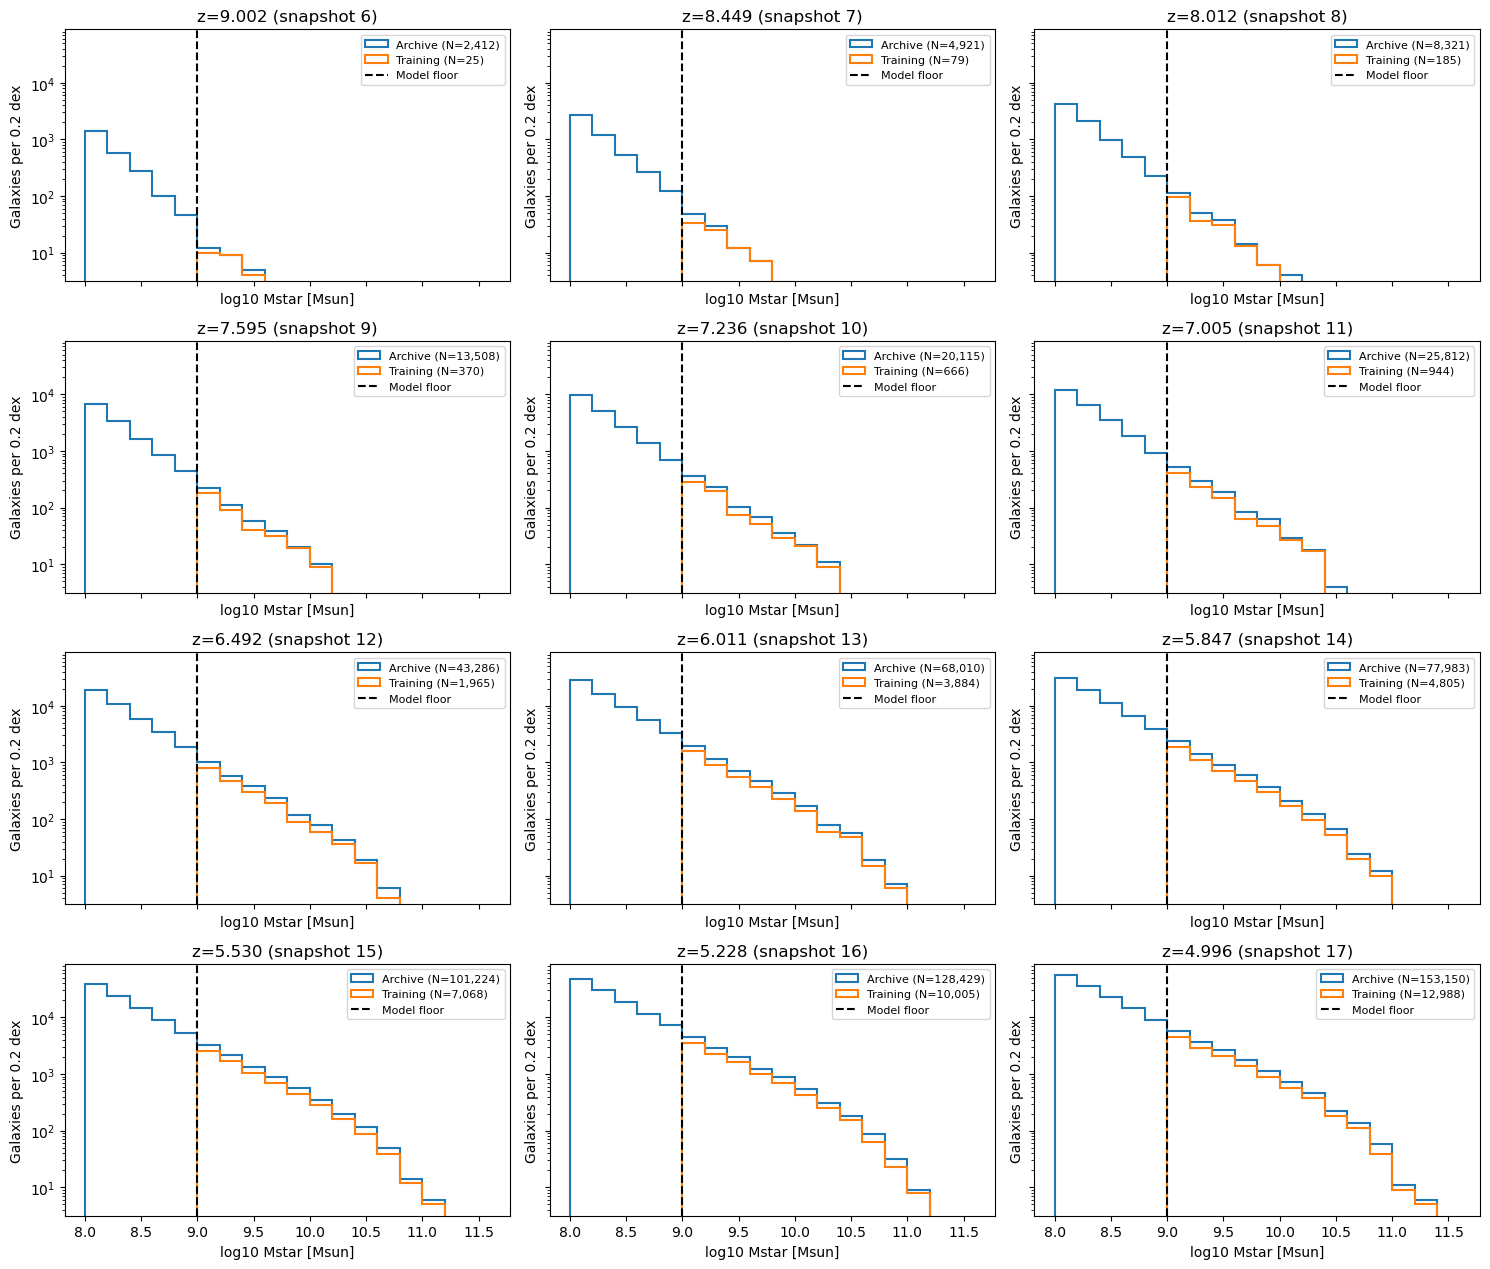

z=0 FoF hosts: total=17,625,892; positive finite M200c=11,461,519; excluded=6,164,373


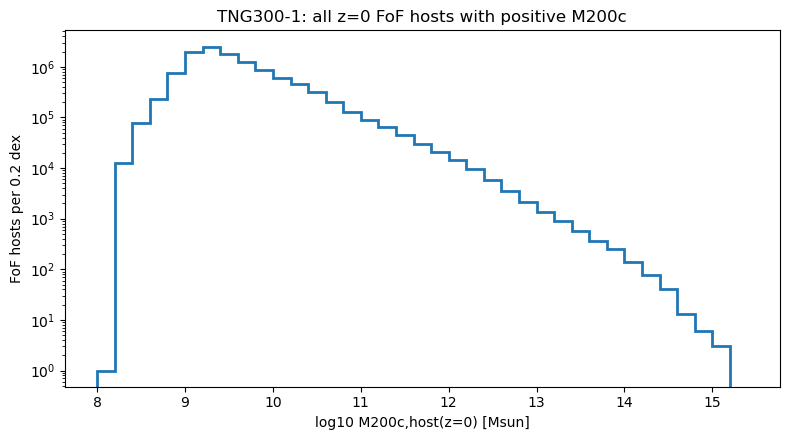

In [12]:
# 各赤方偏移の恒星質量分布：全保存銀河と推論用trainingを比較。
epoch_hist = catalog[['snapshot', 'redshift']].drop_duplicates().sort_values('snapshot')
stellar_values = catalog.logMstar.to_numpy(float)
stellar_values = stellar_values[np.isfinite(stellar_values)]
stellar_bins = np.arange(np.floor(stellar_values.min()*5)/5,
                         np.ceil(stellar_values.max()*5)/5 + .21, .2)
ncols = 3
nrows = int(np.ceil(len(epoch_hist)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.2*nrows),
                         sharex=True, sharey=True, squeeze=False)
stellar_counts = []
for ax, ep in zip(axes.flat, epoch_hist.itertuples(index=False)):
    archived = catalog.loc[catalog.snapshot.eq(ep.snapshot), 'logMstar'].to_numpy(float)
    fitted = train.loc[train.snapshot.eq(ep.snapshot), 'logMstar'].to_numpy(float)
    archived = archived[np.isfinite(archived)]
    fitted = fitted[np.isfinite(fitted)]
    ax.hist(archived, bins=stellar_bins, histtype='step', linewidth=1.5,
            label=f'Archive (N={len(archived):,})')
    ax.hist(fitted, bins=stellar_bins, histtype='step', linewidth=1.5,
            label=f'Training (N={len(fitted):,})')
    ax.axvline(MODEL_LOGMSTAR_MIN, color='k', linestyle='--', label='Model floor')
    ax.set(title=f'z={ep.redshift:.3f} (snapshot {int(ep.snapshot)})',
           xlabel='log10 Mstar [Msun]', ylabel='Galaxies per 0.2 dex', yscale='log')
    ax.legend(fontsize=8)
    na, _ = np.histogram(archived, bins=stellar_bins)
    nt, _ = np.histogram(fitted, bins=stellar_bins)
    for lo, hi, ca, ct in zip(stellar_bins[:-1], stellar_bins[1:], na, nt):
        stellar_counts.append(dict(snapshot=int(ep.snapshot), redshift=float(ep.redshift),
                                   logMstar_left=lo, logMstar_right=hi,
                                   N_archive=int(ca), N_training=int(ct)))
for ax in list(axes.flat)[len(epoch_hist):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(RESULTS/'stellar_mass_histograms.png', dpi=160)
pd.DataFrame(stellar_counts).to_csv(RESULTS/'stellar_mass_histograms.csv', index=False)
plt.show()

# シミュレーション全体のz=0ホスト：Group catalogなので各FoFを1回だけ数える。
import illustris_python as il
header_z0_hist = il.groupcat.loadHeader(str(BASE), 99)
host_mass_z0_hist = np.asarray(
    il.groupcat.loadHalos(str(BASE), 99, fields='Group_M_Crit200'), dtype=float
) * 1e10 / float(header_z0_hist['HubbleParam'])
valid_host_hist = np.isfinite(host_mass_z0_hist) & (host_mass_z0_hist > 0)
print(f'z=0 FoF hosts: total={len(host_mass_z0_hist):,}; '
      f'positive finite M200c={int(valid_host_hist.sum()):,}; '
      f'excluded={int((~valid_host_hist).sum()):,}')
log_host_mass_hist = np.log10(host_mass_z0_hist[valid_host_hist])
if not len(log_host_mass_hist):
    raise ValueError('No positive finite z=0 host masses')
host_bins = np.arange(np.floor(log_host_mass_hist.min()*5)/5,
                      np.ceil(log_host_mass_hist.max()*5)/5 + .21, .2)
fig, ax = plt.subplots(figsize=(8, 4.5))
host_counts, _, _ = ax.hist(log_host_mass_hist, bins=host_bins, histtype='step', linewidth=2)
ax.set(xlabel='log10 M200c,host(z=0) [Msun]', ylabel='FoF hosts per 0.2 dex',
       title='TNG300-1: all z=0 FoF hosts with positive M200c', yscale='log')
fig.tight_layout()
fig.savefig(RESULTS/'all_z0_host_mass_histogram.png', dpi=160)
pd.DataFrame(dict(logM0_left=host_bins[:-1], logM0_right=host_bins[1:],
                  N_hosts=host_counts.astype(int))).to_csv(
    RESULTS/'all_z0_host_mass_histogram.csv', index=False)
plt.show()


青線の条件付き分布に、橙破線の基準分布を重ねます。基準分布は同じ時刻のtraining銀河
（推論質量下限以上・追跡成功）を銀河ごとに等重みで数えた最終ホスト質量分布です。
両者に同じ最終質量の平滑化幅を使い、時刻間では同じ補間比率で混合します。
基準分布は個別の恒星質量・SFRを条件に含みません。SFRを指定した場合は、その情報も加えた分布との比較です。
基準分布と条件付き分布の中央値・区間を表で比較でき、CSVには両方のPDF/CDFを保存します。

## 複数QUERYを重ねて比較
`QUERIES` に比較する入力条件を並べます。色でQUERY、線種でモデルを区別します。
基準分布は同じ赤方偏移の全training銀河を等重みで数え、**黒破線1本**で表示します。
凡例に `MODEL_LOGMSTAR_MIN` の恒星質量下限を表示します。出力側の平滑化幅は恒星質量のみのCV選択値に固定し、QUERYの順序によって変えません。
基準分布は個別の恒星質量・SFR・周辺銀河数では条件付けません。
`SHOW_BASELINE=True` では全QUERYを同じ赤方偏移にそろえてください。異なる時刻を重ねる場合はFalseにします。
`SHOW_INTERVALS=True` で条件付き分布の68%帯と中央値を表示できます。
比較表・PDF/CDF・設定JSON・図を保存します。基準分布はquery_index=0として1回だけ保存します。

同じセルの `FONT_SIZES` で軸ラベル（axis_label）・目盛り（tick）・凡例（legend）・タイトル（title）のサイズをポイント単位で指定できます。


/tmp/ipykernel_11616/176601833.py:45: UserWarning: Query is close to the model stellar-mass floor. Check sensitivity to a lower floor; the result is conditional on the selected population.
  warnings.warn('Query is close to the model stellar-mass floor. Check sensitivity to a lower floor; '
/tmp/ipykernel_11616/176601833.py:48: UserWarning: Interpolating conditional PDFs between snapshots; interpolation has not been validated by the per-snapshot test. Epoch details are returned.
  warnings.warn('Interpolating conditional PDFs between snapshots; interpolation has not been '
/tmp/ipykernel_11616/176601833.py:45: UserWarning: Query is close to the model stellar-mass floor. Check sensitivity to a lower floor; the result is conditional on the selected population.
  warnings.warn('Query is close to the model stellar-mass floor. Check sensitivity to a lower floor; '
/tmp/ipykernel_11616/176601833.py:48: UserWarning: Interpolating conditional PDFs between snapshots; interpolation has not been 

,query_index,query,curve,q025,q16,median,q84,q975,p_ge_1e13,p_ge_1e14,...,ESS_host,z,logMstar,sfr,feature_set,epochs,support_ok,population,model,model_logmstar_min
0,1,"Q1: z=6, logMstar=10, SFR=None",Conditional,12.479004,13.117642,13.850595,14.519412,15.121960,0.877208,0.414387,...,442.807146,6.0,10.0,NaN,mstar,"[{'snapshot': 14, 'z': 5.846613747881867, 'wei...",True,physical galaxies above model mass floor; succ...,empirical joint KDE; simulation conditional; e...,NaN
1,2,"Q2: z=6, logMstar=10, SFR=10.0",Conditional,12.395103,13.027640,13.785713,14.475544,15.102278,0.849058,0.382667,...,531.375498,6.0,10.0,10.0,mstar_sfr,"[{'snapshot': 14, 'z': 5.846613747881867, 'wei...",True,physical galaxies above model mass floor; succ...,empirical joint KDE; simulation conditional; e...,NaN
2,0,"Baseline: z=6, log10(Mstar/Msun) >= 9",Baseline,12.366572,12.999225,13.779447,14.481193,15.099620,0.839750,0.382894,...,563.071719,6.0,NaN,NaN,NaN,"[{'snapshot': 14, 'z': 5.846613747881867, 'wei...",NaN,"same training galaxies, equal galaxy weights",NaN,9.0


,query_index,query,curve,snapshot,z,weight
0,1,"Q1: z=6, logMstar=10, SFR=None",Conditional,14,5.846614,0.0641
1,1,"Q1: z=6, logMstar=10, SFR=None",Conditional,13,6.010757,0.9359
2,2,"Q2: z=6, logMstar=10, SFR=10.0",Conditional,14,5.846614,0.0641
3,2,"Q2: z=6, logMstar=10, SFR=10.0",Conditional,13,6.010757,0.9359
4,0,"Baseline: z=6, log10(Mstar/Msun) >= 9",Baseline,14,5.846614,0.0641
5,0,"Baseline: z=6, log10(Mstar/Msun) >= 9",Baseline,13,6.010757,0.9359


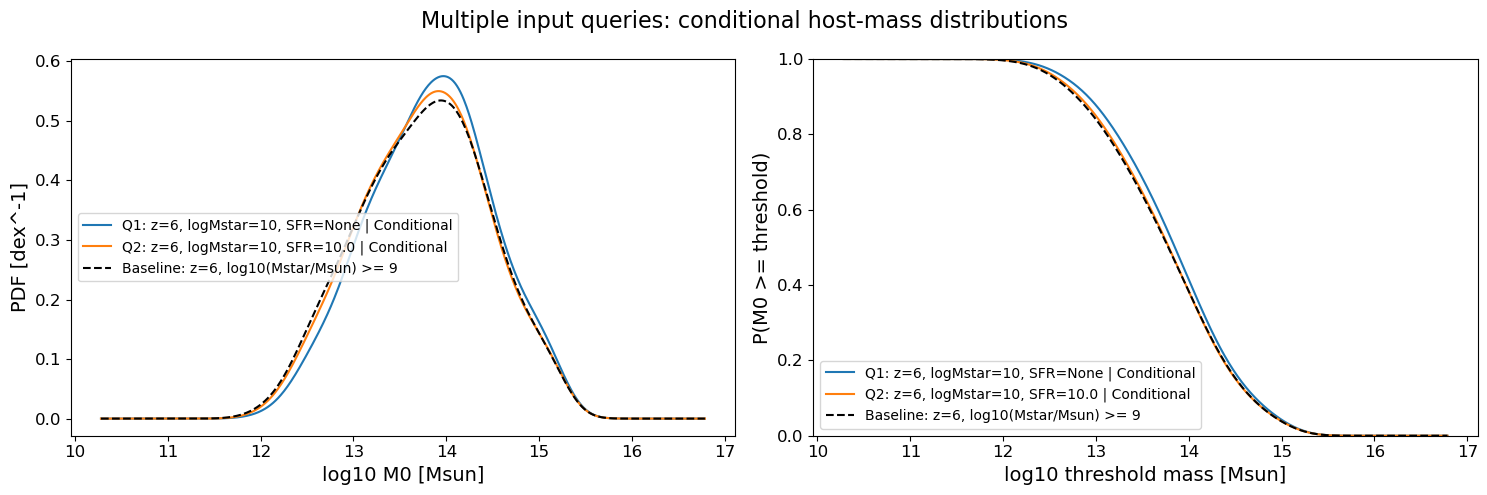

Results: /home/tnguser/tng-work/protohalo/cache/tng300_bayesian_latent_results/inference_b4748b528af740da


In [14]:
model = LatentHostModel(train, selected, MODEL_LOGMSTAR_MIN)
# Add/remove dictionaries to compare any number of inputs; values here are examples.
QUERIES = [
    {'z': 6.0, 'logMstar': 10.0, 'sfr': None},
    {'z': 6.0, 'logMstar': 10.0, 'sfr': 10.0},
]
# Font sizes in points (applied only to this final figure).
FONT_SIZES = dict(axis_label=14, tick=12, legend=10, title=16)
SHOW_INTERVALS = False  # Optional central 68% bands and medians; off to avoid clutter.
if not QUERIES:
    raise ValueError('QUERIES must contain at least one input')
SHOW_BASELINE = True
if SHOW_BASELINE and not all(float(q['z']) == float(QUERIES[0]['z']) for q in QUERIES):
    raise ValueError('A single baseline requires the same z for all QUERIES. '
                     'Use a common z or set SHOW_BASELINE=False.')
curves, query_labels = [], []
STYLES = {'Conditional': '-', 'Baseline': '--'}
for qi, query in enumerate(QUERIES):
    query_labels.append(f"Q{qi+1}: z={query['z']:g}, logMstar={query['logMstar']:g}, SFR={query.get('sfr')}")
    posterior = model.posterior(**query)
    curves.append((qi, 'Conditional', posterior))

# One common galaxy-weighted baseline. Fix its width to the mstar-only CV choice
# so it does not depend on query order or SFR/environment model bandwidths.
if SHOW_BASELINE:
    parts, weights, hosts, baseline_epochs = [], [], [], []
    for ep in curves[0][2].metadata['epochs']:
        part = model.train.loc[model.train.snapshot.eq(ep['snapshot'])]
        parts.append(part.logM0.to_numpy(float))
        weights.append(np.full(len(part), ep['weight']/len(part)))
        hosts.append(part.GroupID_z0.to_numpy())
        baseline_epochs.append({k: ep[k] for k in ['snapshot','z','weight']})
    baseline = Posterior(np.concatenate(parts), np.concatenate(weights),
                         model.selected['mstar']['ywidth'], np.concatenate(hosts),
                         metadata={'epochs': baseline_epochs, 'z': float(QUERIES[0]['z']),
                                   'model_logmstar_min': model.logmstar_min,
                                   'population': 'same training galaxies, equal galaxy weights'})
    baseline_label = (f'Baseline: z={QUERIES[0]["z"]:g}, '
                      f'log10(Mstar/Msun) >= {model.logmstar_min:g}')
    curves.append((-1, 'Baseline', baseline))

# Use one grid for every query/model, including different smoothing widths.
grid = np.linspace(min(p.means.min()-8*p.width for _,_,p in curves),
                   max(p.means.max()+8*p.width for _,_,p in curves), 700)
fig, axes = plt.subplots(1, 2, figsize=(15,5))
summary_rows, density_tables, support_rows = [], [], []
for qi, name, p in curves:
    curve_query_label = baseline_label if name == 'Baseline' else query_labels[qi]
    color = 'black' if name == 'Baseline' else f'C{qi % 10}'
    supported = p.metadata.get('support_ok', True)
    style = STYLES[name] if supported else ':'
    label = baseline_label if name == 'Baseline' else f"{query_labels[qi]} | {name}"
    if not supported:
        label += ' [UNSUPPORTED: diagnostic only]'
    density = np.array([np.exp(p.logpdf(x)) for x in grid])
    cdf = np.array([p.cdf(x) for x in grid])
    axes[0].plot(grid, density, color=color, linestyle=style, label=label)
    axes[1].plot(grid, 1-cdf, color=color, linestyle=style, label=label)
    summary_rows.append(dict(query_index=qi+1, query=curve_query_label, curve=name, **p.summary()))
    density_tables.append(pd.DataFrame(dict(query_index=qi+1, query=curve_query_label,
        curve=name, logM0=grid, pdf_per_dex=density, cdf=cdf, support_ok=supported)))
    for ep in p.metadata.get('epochs', []):
        support_rows.append(dict(query_index=qi+1, query=curve_query_label, curve=name, **ep))
    if SHOW_INTERVALS and name != 'Baseline':
        axes[0].axvspan(p.quantile(.16), p.quantile(.84), color=color, alpha=.07)
        axes[0].axvline(p.quantile(.5), color=color, alpha=.4, linewidth=.8)
axes[0].set(xlabel='log10 M0 [Msun]', ylabel='PDF [dex^-1]')
axes[1].set(xlabel='log10 threshold mass [Msun]', ylabel='P(M0 >= threshold)', ylim=(0,1))
for ax in axes:
    ax.xaxis.label.set_fontsize(FONT_SIZES['axis_label'])
    ax.yaxis.label.set_fontsize(FONT_SIZES['axis_label'])
    ax.tick_params(axis='both', labelsize=FONT_SIZES['tick'])
    ax.legend(fontsize=FONT_SIZES['legend'])
if any(not p.metadata.get('support_ok', True) for _,_,p in curves):
    fig.suptitle('Dotted unsupported curves are diagnostic only', color='crimson')
else:
    fig.suptitle('Multiple input queries: conditional host-mass distributions')
plt.setp(fig.texts, fontsize=FONT_SIZES['title'])
fig.tight_layout()
batch_id = hashlib.sha256(json.dumps(QUERIES, sort_keys=True).encode()).hexdigest()[:12]
summary_table = pd.DataFrame(summary_rows)
display(summary_table)
summary_table.to_csv(RESULTS/f'queries_{batch_id}_summary.csv', index=False)
pd.concat(density_tables, ignore_index=True).to_csv(RESULTS/f'queries_{batch_id}_pdf.csv', index=False)
if support_rows:
    support_table = pd.DataFrame(support_rows)
    display(support_table)
    support_table.to_csv(RESULTS/f'queries_{batch_id}_support.csv', index=False)
(RESULTS/f'queries_{batch_id}.json').write_text(json.dumps(
    dict(queries=QUERIES, summaries=summary_rows), indent=2))
fig.savefig(RESULTS/f'queries_{batch_id}.png', dpi=160)
plt.show()
print('Results:', RESULTS.resolve())


## 再開・次の段階
- 標本構築を再実行すると完了済みCSV・追跡結果を利用します。入力ファイルの更新や保存下限変更は新しい保存先になります。
- 次回は `pd.read_csv(CATALOG_DIR/'galaxies_all.csv')` と保存した帯域幅・splitから復元可能です。
- SFR追加の効果は未使用testのNLL/包含率を比較します。個別銀河の区間が必ず狭くなるとは限りません。
- 本版は観測selection・環境量の構築・観測誤差モデル・追観測の期待情報利得をまだ実装していません。
- 本版の区間は $M_0$ の条件付き分布です。有限標本、帯域幅選択、TNG物理モデルの不確実性は別途評価が必要です。
- 正規分布カーネルの裾は標本最大質量の外にも延びます。未出現の超高質量ホストの存在量を検証したことにはなりません。

### 参考
- [TNGデータ仕様](https://www.tng-project.org/data/docs/specifications/)
- [公式SubLink読み込み実装](https://github.com/illustristng/illustris_python/blob/master/illustris_python/sublink.py)
- [Simulation-based inferenceのレビュー](https://arxiv.org/abs/1911.01429)
